# Subsequent elbow injury in MLB pitchers: fastball-velocity EWMA-CUSUM charts

**Question.** Among pitchers who return from an **initial elbow IL placement**, can a game-by-game
control chart on fastball velocity flag the pitchers who go on to a **subsequent elbow IL placement**
the same season, before it happens?

**Cohort and outcome**

| | Definition |
|---|---|
| Unit | One pitcher-season with an elbow IL placement (the first elbow placement that season), first return by August 31, at least 5 post-return appearances |
| Case | A later IL placement that season, after the return, for the elbow (first non-COVID placement after the return is an elbow placement) |
| Control | No later elbow placement that season. If the next placement is for something else (shoulder, oblique, ...), the pitcher stays a control and his chart **stops at that IL date** |
| "Elbow" | Elbow, UCL / Tommy John, ulnar nerve, flexor / pronator, forearm, epicondyle, olecranon, valgus, internal brace; "non-throwing" excluded |

**Statistics monitored, one value per game**, from the pitcher's primary fastball (four-seam or sinker,
whichever he threw more before the injury), in games with at least 8 primary fastballs:

* **CV** = 100 × SD / mean of fastball velocity in that game. Hypothesis: CV **rises** before an elbow injury → **upper-sided** chart.
* **Mean velocity** in that game. Hypothesis: velocity **drops** → **lower-sided** chart (the same direction as the NBA study).

**Chart.** The EWMA-CUSUM from the NBA study. For the lower-sided chart (as in the NBA paper):

$$\text{PCI}_{\text{lower},j} = \frac{x_j - \text{LSL}}{\sigma_0},\quad \text{LSL} = \mu_0 - 2\sigma_0,\qquad
c_j = \min\{0,\ \lambda(\text{PCI}_{\text{lower},j} - 2) + (1-\lambda)c_{j-1}\},\quad \text{signal if } c_j < -h.$$

The upper-sided chart for CV is the mirror image:

$$\text{PCI}_{\text{upper},j} = \frac{\text{USL} - x_j}{\sigma_0},\quad \text{USL} = \mu_0 + 2\sigma_0,\qquad
c_j = \max\{0,\ \lambda(2 - \text{PCI}_{\text{upper},j}) + (1-\lambda)c_{j-1}\},\quad \text{signal if } c_j > h.$$

Both reduce to the same recursion on $z_j = (x_j-\mu_0)/\sigma_0$, with the sign flipped for the lower side.

**Baseline (Approach B of the NBA study).** $\mu_0$ is the pitcher's mean over his games in the 365 days
before the initial elbow injury, shrunk toward the grand mean with the empirical-Bayes weight
$k = \sigma^2_{\text{within}}/\sigma^2_{\text{between}}$ (one-way random-effects ANOVA, Henderson's Method I);
$\sigma_0$ is the pooled within-pitcher SD. The grand mean, $k$ and $\sigma_0$ are estimated from the
**training seasons only**.

**Evaluation (as in the NBA study).** (λ, h) grid on the training seasons, selection on training-season
accuracy, a block-bootstrap false-alarm check, ROC frontier and AUC, then one application of the frozen
model to the held-out season. A unit is a predicted positive if the chart signals in any monitored game
(every monitored game comes before the subsequent IL date, so every signal is a warning ahead of it).

**Data.** The injury workbook (`MLB Injuries Raw Data.xlsx`), the Chadwick register for FanGraphs → MLBAM
IDs, and Baseball Savant pitch-by-pitch data. Everything is cached in `data/`; the Statcast cache from the
replication notebook (`data/statcast/`) is reused where it covers the needed dates, and only missing date
ranges are downloaded.

Run top to bottom. All rules are in the Settings cell.

## 1. Settings

In [1]:
from pathlib import Path
import io
import re
import time
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

WORKSPACE = Path.cwd()
DATA_DIR = WORKSPACE / "data"
DATA_DIR.mkdir(exist_ok=True)
STATCAST_CACHE = DATA_DIR / "statcast"              # shared with the replication notebook
STATCAST_CACHE.mkdir(exist_ok=True)
CHADWICK_CACHE = DATA_DIR / "chadwick_register_ids.csv"
OUT_DIR = DATA_DIR / "elbow_ewma_cusum"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
INJURY_WORKBOOK = WORKSPACE / "MLB Injuries Raw Data.xlsx"
if not INJURY_WORKBOOK.exists():
    raise FileNotFoundError(f"Expected workbook was not found: {INJURY_WORKBOOK}")

# ---- Seasons ----
TRAIN_SEASONS = [2021, 2022, 2023, 2024]
TEST_SEASON = 2025                  # held out: used once, in Section 9
SEASONS = TRAIN_SEASONS + [TEST_SEASON]

# ---- Cohort rules ----
PITCHER_POSITIONS = {"RP", "SP", "SP/RP", "RP/SP", "P"}
FIRST_RETURN_CUTOFF = "08-31"       # first return by August 31 (as in the WHIP paper)
MIN_POST_RETURN_APPS = 5            # at least 5 post-return appearances (as in the WHIP paper)
ELBOW_PATTERN = re.compile(
    r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|valgus|internal brace",
    flags=re.IGNORECASE,
)
COVID_PATTERN = re.compile(r"covid", flags=re.IGNORECASE)

# ---- Game-level statistics ----
FASTBALLS = ["FF", "SI"]            # primary fastball = whichever he threw more before the injury
LOOKBACK_DAYS = 365                 # baseline window before the initial elbow injury
MIN_FB_GAME = 8                     # a game needs >= 8 primary fastballs to give a mean / SD / CV
CV_FIRST_N = None                   # e.g. 20 = use only his first 20 primary fastballs in each game
SIGMA_MODE = "pooled"               # "pooled" (NBA study) or "per_fb" (sigma scaled by 1/sqrt(fastballs))

METRICS = {
    "cv":   {"label": "Fastball velocity CV (%)",     "side": "upper"},   # signal on a rise
    "velo": {"label": "Mean fastball velocity (mph)", "side": "lower"},   # signal on a drop
}

# ---- Chart grid (NBA study) ----
LAMBDA_GRID = np.round(np.arange(0.45, 0.951, 0.10), 2)           # 0.45 ... 0.95
LAMBDA_GRID_LOW = np.round(np.arange(0.05, 0.351, 0.10), 2)       # sensitivity check: 0.05 ... 0.35
H_GRID = np.round(np.arange(0.05, 0.501, 0.05), 2)                # 0.05 ... 0.50
H_GRID_WIDE = np.round(np.r_[np.arange(0.05, 0.501, 0.05), np.arange(0.75, 5.001, 0.25)], 2)
SELECTION_RULE = "accuracy"         # NBA study; "youden" is also reported

# ---- Block-bootstrap false-alarm check ----
N_NULL_SEQUENCES = 5000
BLOCK_LEN = 3
SEED = 2026

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


print("Training seasons:", TRAIN_SEASONS, "| held-out season:", TEST_SEASON)
print("Outputs:", OUT_DIR)

Training seasons: [2021, 2022, 2023, 2024] | held-out season: 2025
Outputs: /workspaces/Sports-Analytics-and-Intelligence-Lab/MLB Pitcher Injuries/data/elbow_ewma_cusum


## 2. Injury records

Loads every season sheet, keeps pitcher rows with an IL date, and classifies each description as elbow /
not elbow and COVID / not COVID. Pitchers are keyed by **FanGraphs ID** rather than name, so accented
names cannot break the join (the issue behind the Table 2 baseline row). If a sheet has no
`key_fangraphs` column, the ID is read from the FanGraphs URL.

For the baseline window, the injury date is the **earlier** of the injury/surgery date and the IL date.
This matters for stints carried over from a previous season (e.g. Tommy John surgery the year before):
their IL date is opening day, but the pre-injury games are the ones before the surgery.

In [2]:
def clean_id(value):
    """IDs as plain strings: 12447.0 -> '12447', ' sa3012 ' -> 'sa3012'."""
    if pd.isna(value):
        return None
    text = str(value).strip()
    if not text:
        return None
    return text[:-2] if text.endswith(".0") else text


def fangraphs_id(row):
    value = clean_id(row.get("key_fangraphs"))
    if value:
        return value
    for column in ["URL", "sub_url"]:
        text = row.get(column)
        if isinstance(text, str):
            match = (re.search(r"/players/[^/]+/([^/?#]+)", text)
                     or re.match(r"[^/]+/([^/?#]+)/", text))
            if match:
                return match.group(1)
    return None


excel_file = pd.ExcelFile(INJURY_WORKBOOK)
tables = []
for sheet in excel_file.sheet_names:
    try:
        season = int(str(sheet).strip())
    except ValueError:
        continue
    if season in SEASONS:
        table = pd.read_excel(excel_file, sheet_name=sheet)
        table["Season"] = season
        tables.append(table)
missing_sheets = sorted(set(SEASONS) - {int(t["Season"].iloc[0]) for t in tables if len(t)})
if missing_sheets:
    raise ValueError(f"Workbook has no sheet for seasons {missing_sheets}")

injuries = pd.concat(tables, ignore_index=True).rename(columns={
    "IL Retro Date": "IL_Date", "Return Date": "Return_Date",
    "Injury / Surgery": "Injury", "Injury / Surgery Date": "Injury_Date"})
for column in ["IL_Date", "Return_Date", "Injury_Date"]:
    if column not in injuries.columns:
        injuries[column] = pd.NaT
    injuries[column] = pd.to_datetime(injuries[column], errors="coerce")

injuries["Pos"] = injuries["Pos"].astype(str).str.strip().str.upper()
injuries["Injury"] = injuries["Injury"].fillna("").astype(str).str.strip()
injuries["FanGraphs_ID"] = injuries.apply(fangraphs_id, axis=1)
injuries["pkey"] = injuries["FanGraphs_ID"].where(injuries["FanGraphs_ID"].notna(),
                                                  "name:" + injuries["Name"].astype(str))
injuries = injuries.loc[injuries["Pos"].isin(PITCHER_POSITIONS) & injuries["IL_Date"].notna()].copy()
injuries = injuries.drop_duplicates(["pkey", "Season", "IL_Date", "Injury"])
injuries["is_covid"] = injuries["Injury"].str.contains(COVID_PATTERN)
injuries["is_elbow"] = (injuries["Injury"].str.contains(ELBOW_PATTERN)
                        & ~injuries["Injury"].str.contains("non-throwing", case=False))
injuries["onset"] = injuries[["Injury_Date", "IL_Date"]].min(axis=1)
injuries = injuries.sort_values(["pkey", "Season", "IL_Date"], kind="stable").reset_index(drop=True)

display(injuries.groupby("Season").agg(pitcher_IL_rows=("pkey", "size"),
                                      elbow_rows=("is_elbow", "sum"),
                                      covid_rows=("is_covid", "sum"),
                                      missing_fangraphs_id=("FanGraphs_ID", lambda s: int(s.isna().sum()))))

# Every description and how it was classified, for a line-by-line check of the rule.
classification_review = (injuries.loc[~injuries["is_covid"]]
                         .groupby(["is_elbow", "Injury"]).size().rename("IL rows").reset_index()
                         .sort_values(["is_elbow", "IL rows"], ascending=[False, False]))
classification_review.to_csv(OUT_DIR / "elbow_classification_review.csv", index=False)
print("Elbow descriptions:")
with pd.option_context("display.max_rows", 200):
    display(classification_review.loc[classification_review["is_elbow"]])
print("Most common non-elbow descriptions (full list in elbow_classification_review.csv):")
display(classification_review.loc[~classification_review["is_elbow"]].head(25))

,pitcher_IL_rows,elbow_rows,covid_rows,missing_fangraphs_id
Season,,,,
2021,687,153,130,0
2022,559,147,10,0
2023,502,158,2,0
2024,483,175,2,0
2025,458,163,0,0


Elbow descriptions:


,is_elbow,Injury,IL rows
449,True,Tommy John surgery,249
380,True,Elbow inflammation,126
443,True,Strained forearm,65
372,True,Elbow discomfort,28
438,True,Sprained elbow,28
423,True,Forearm inflammation,23
439,True,Strained elbow,21
402,True,Elbow surgery (internal brace),20
440,True,Strained elbow flexor,18
415,True,Flexor tendon surgery,16


Most common non-elbow descriptions (full list in elbow_classification_review.csv):


,is_elbow,Injury,IL rows
219,False,Shoulder inflammation,149
299,False,Strained shoulder,109
293,False,Strained oblique,106
281,False,Strained hamstring,91
217,False,Shoulder impingement,72
280,False,Strained groin,70
356,False,Undisclosed,63
286,False,Strained lat,59
288,False,Strained lower back,44
273,False,Strained calf,34


## 3. Cohort: initial elbow IL placement → subsequent elbow IL placement

For each pitcher-season, the **initial** placement is his first elbow placement of that season. The
**next** non-COVID placement after his return decides the outcome: elbow → case (chart runs up to that IL
date); anything else → control, chart stops at that IL date; none → control, chart runs to the end of the
season.

In [3]:
elbow = injuries.loc[injuries["is_elbow"] & ~injuries["is_covid"]]
units = (elbow.groupby(["pkey", "Season"], as_index=False, sort=False).head(1)
              [["pkey", "Name", "Season", "FanGraphs_ID", "Team", "Pos", "Injury", "Injury_Date",
                "IL_Date", "onset", "Return_Date"]]
              .rename(columns={"Injury": "initial_injury"})
              .reset_index(drop=True))
funnel = [("Pitcher-seasons with an elbow IL placement", len(units))]

cutoff = pd.to_datetime(units["Season"].astype(str) + "-" + FIRST_RETURN_CUTOFF)
units = units.loc[units["Return_Date"].notna()]
funnel.append(("... with a return date", len(units)))
units = units.loc[units["Return_Date"] >= units["IL_Date"]]
funnel.append(("... return on or after the IL date", len(units)))
units = units.loc[units["Return_Date"] <= cutoff.loc[units.index]].copy()
funnel.append((f"... first return by {FIRST_RETURN_CUTOFF}", len(units)))

# Next non-COVID IL placement after the return, same season.
later = injuries.loc[~injuries["is_covid"], ["pkey", "Season", "IL_Date", "Injury", "is_elbow"]].merge(
    units[["pkey", "Season", "Return_Date"]], on=["pkey", "Season"])
later = later.loc[later["IL_Date"] > later["Return_Date"]].sort_values(["pkey", "Season", "IL_Date"])
next_il = later.groupby(["pkey", "Season"], as_index=False).head(1)
any_later_elbow = later.loc[later["is_elbow"]].groupby(["pkey", "Season"]).size().rename("n_later_elbow")

units = units.merge(next_il[["pkey", "Season", "IL_Date", "Injury", "is_elbow"]]
                    .rename(columns={"IL_Date": "next_il_date", "Injury": "next_injury",
                                     "is_elbow": "next_is_elbow"}),
                    on=["pkey", "Season"], how="left")
units = units.merge(any_later_elbow, left_on=["pkey", "Season"], right_index=True, how="left")
units["next_is_elbow"] = units["next_is_elbow"].astype("boolean").fillna(False).astype(bool)
units["case"] = units["next_is_elbow"].astype(int)
units["event_date"] = units["next_il_date"].where(units["case"] == 1)
units["censor_date"] = units["next_il_date"].where(units["case"] == 0)
units["stop_date"] = units["next_il_date"].fillna(pd.to_datetime(units["Season"].astype(str) + "-12-31")
                                                  + pd.Timedelta(days=1))
units["outcome"] = np.select(
    [units["case"] == 1, units["censor_date"].notna()],
    ["case: subsequent elbow IL", "control: stopped at non-elbow IL"],
    default="control: no later IL")

n_elbow_after_other = int(((units["case"] == 0) & units["n_later_elbow"].notna()).sum())
print("Controls whose next placement was non-elbow but who had an elbow placement later that season:",
      n_elbow_after_other, "(kept as controls, as specified)")
display(pd.crosstab(units["Season"], units["outcome"], margins=True))

Controls whose next placement was non-elbow but who had an elbow placement later that season: 3 (kept as controls, as specified)


outcome,case: subsequent elbow IL,control: no later IL,control: stopped at non-elbow IL,All
Season,,,,
2021,13,30,14,57
2022,10,25,14,49
2023,9,29,9,47
2024,11,36,13,60
2025,6,28,17,51
All,49,148,67,264


## 4. MLBAM IDs and Baseball Savant pitch data

Statcast uses MLBAM IDs, linked to FanGraphs IDs by the Chadwick register (cached by the replication
notebook; downloaded here if missing). Each pitcher's window runs from 365 days before the initial elbow
injury to November 30 of the monitored season. Cached files from the replication notebook are used when
they cover the window; otherwise only the missing earlier dates are downloaded and cached as a separate
file.

In [4]:
CHADWICK_URL = "https://raw.githubusercontent.com/chadwickbureau/register/master/data/people-{}.csv"
if CHADWICK_CACHE.exists():
    id_map = pd.read_csv(CHADWICK_CACHE, dtype=str)
else:
    parts = []
    for suffix in "0123456789abcdef":
        part = pd.read_csv(CHADWICK_URL.format(suffix), usecols=["key_mlbam", "key_fangraphs"],
                           dtype=str, low_memory=False)
        parts.append(part.dropna())
        time.sleep(0.5)
    id_map = pd.concat(parts, ignore_index=True)
    id_map.to_csv(CHADWICK_CACHE, index=False)
fg_to_mlbam = dict(zip(id_map["key_fangraphs"].map(clean_id), id_map["key_mlbam"].map(clean_id)))

units["mlbam"] = units["FanGraphs_ID"].map(lambda v: fg_to_mlbam.get(v) if v else None)
no_id = units.loc[units["mlbam"].isna(), ["Name", "Season", "FanGraphs_ID"]]
if len(no_id):
    print("No MLBAM ID (dropped):")
    display(no_id)
units = units.loc[units["mlbam"].notna()].copy()
units["mlbam"] = units["mlbam"].astype(int)
funnel.append(("... with an MLBAM ID", len(units)))
units["window_start"] = (units["onset"] - pd.Timedelta(days=LOOKBACK_DAYS)).dt.normalize()
units["window_end"] = pd.to_datetime(units["Season"].astype(str) + "-11-30")
print("Pitcher-seasons to download:", len(units))

No MLBAM ID (dropped):


,Name,Season,FanGraphs_ID
262,Dylan File,2021,sa3004197
263,Daniel Tillo,2021,sa876284


Pitcher-seasons to download: 262


In [5]:
SAVANT_URL = (
    "https://baseballsavant.mlb.com/statcast_search/csv?all=true&type=details&player_type=pitcher"
    "&hfGT=R%7C&hfSea=&game_date_gt={start}&game_date_lt={end}&pitchers_lookup%5B%5D={mlbam}"
    "&min_pitches=0&min_results=0&min_abs=0&group_by=name&sort_col=pitches&sort_order=desc"
)
SAVANT_KEEP = ["pitcher", "game_pk", "game_date", "game_type", "inning", "at_bat_number",
               "pitch_number", "pitch_type", "release_speed", "p_throws"]
CACHE_NAME = re.compile(r"(\d+)_(\d{8})_(\d{8})\.csv")


def download_statcast(mlbam, start, end, sleep_seconds=2.0, retries=3):
    """One Savant request (regular season), saved in the shared cache with the same file naming."""
    path = STATCAST_CACHE / f"{mlbam}_{start:%Y%m%d}_{end:%Y%m%d}.csv"
    if path.exists():
        return pd.read_csv(path)
    url = SAVANT_URL.format(mlbam=mlbam, start=f"{start:%Y-%m-%d}", end=f"{end:%Y-%m-%d}")
    for attempt in range(1, retries + 1):
        try:
            time.sleep(sleep_seconds)
            request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urlopen(request, timeout=120) as response:
                text = response.read().decode("utf-8-sig")
            break
        except Exception as error:
            print(f"  attempt {attempt} failed for {mlbam}: {error!r}")
            time.sleep(10 * attempt)
    else:
        raise RuntimeError(f"Could not download Statcast data for pitcher {mlbam}")
    data = pd.read_csv(io.StringIO(text)) if text.strip() else pd.DataFrame(columns=SAVANT_KEEP)
    required = set(SAVANT_KEEP) - {"p_throws"}
    if len(data) and required - set(data.columns):
        raise ValueError(f"Unexpected Savant response for {mlbam}: {text[:300]!r}")
    if "game_type" in data.columns:
        data = data.loc[data["game_type"] == "R"]
    data = data[[c for c in SAVANT_KEEP if c in data.columns]]
    data.to_csv(path, index=False)
    return data


def cached_files(mlbam):
    out = []
    for path in STATCAST_CACHE.glob(f"{mlbam}_*.csv"):
        match = CACHE_NAME.fullmatch(path.name)
        if match and int(match.group(1)) == mlbam:
            out.append((pd.Timestamp(match.group(2)), pd.Timestamp(match.group(3)), path))
    return out


def statcast_window(mlbam, start, end):
    """Pitches for [start, end], from the cache where possible; downloads only the uncovered part."""
    files = cached_files(mlbam)
    pieces = [pd.read_csv(p) for s, e, p in files if s <= end and e >= start]   # overlapping files
    covered_from = min([s for s, e, p in files if s <= end and e >= end], default=None)
    if covered_from is None:                       # nothing reaches the end date: one full request
        pieces.append(download_statcast(mlbam, start, end))
    elif covered_from > start:                     # fetch only the earlier, uncovered dates
        pieces.append(download_statcast(mlbam, start, covered_from - pd.Timedelta(days=1)))
    pieces = [p for p in pieces if len(p)]
    if not pieces:
        return pd.DataFrame(columns=SAVANT_KEEP)
    data = pd.concat(pieces, ignore_index=True)
    data["game_date"] = pd.to_datetime(data["game_date"])
    return data.loc[data["game_date"].between(start, end)]


pieces, statcast_failures = [], []
for number, (_, row) in enumerate(units.drop_duplicates(["mlbam", "window_start", "window_end"]).iterrows(), 1):
    try:
        pieces.append(statcast_window(row["mlbam"], row["window_start"], row["window_end"]))
    except Exception as error:
        statcast_failures.append({"Name": row["Name"], "Season": row["Season"], "mlbam": row["mlbam"],
                                  "error": repr(error)})
    if number % 50 == 0:
        print(f"{number} windows ({len(statcast_failures)} failures)")
statcast_failures = pd.DataFrame(statcast_failures)
statcast_failures.to_csv(OUT_DIR / "statcast_fetch_failures.csv", index=False)
if len(statcast_failures):
    display(statcast_failures)

pitches = pd.concat(pieces, ignore_index=True)
if "p_throws" not in pitches.columns:
    pitches["p_throws"] = np.nan
pitches = pitches.dropna(subset=["game_pk", "at_bat_number", "pitch_number"]).copy()
pitches["pitcher"] = pitches["pitcher"].astype(int)
pitches["game_pk"] = pitches["game_pk"].astype(int)
pitches["game_date"] = pd.to_datetime(pitches["game_date"])
pitches = (pitches.drop_duplicates(["pitcher", "game_pk", "at_bat_number", "pitch_number"])
                  .sort_values(["pitcher", "game_date", "game_pk", "at_bat_number", "pitch_number"])
                  .reset_index(drop=True))
pitches["pitch_count"] = pitches.groupby(["pitcher", "game_pk"]).cumcount() + 1
pitches_by_pitcher = {p: g for p, g in pitches.groupby("pitcher")}
print(f"Pitches: {len(pitches):,} | pitchers: {pitches['pitcher'].nunique()}")

50 windows (1 failures)
100 windows (6 failures)
150 windows (11 failures)
200 windows (17 failures)
250 windows (19 failures)


,Name,Season,mlbam,error
0,Lucas Sims,2022,608371,"NotImplementedError(""strftime not yet supporte..."
1,Justin Topa,2022,623437,"NotImplementedError(""strftime not yet supporte..."
2,John Means,2024,607644,"NotImplementedError(""strftime not yet supporte..."
3,Erik Swanson,2025,657024,"NotImplementedError(""strftime not yet supporte..."
4,Austin Davis,2021,656354,"NotImplementedError(""strftime not yet supporte..."
5,Michael Kopech,2025,656629,"NotImplementedError(""strftime not yet supporte..."
6,Peter Lambert,2022,663567,"NotImplementedError(""strftime not yet supporte..."
7,Zac Gallen,2021,668678,"NotImplementedError(""strftime not yet supporte..."
8,Matt Foster,2024,641582,"NotImplementedError(""strftime not yet supporte..."
9,Jonathan Loáisiga,2025,642528,"NotImplementedError(""strftime not yet supporte..."


Pitches: 391,863 | pitchers: 218


In [6]:
# Elbow descriptions that name a side: flag any that do not match the throwing arm, for manual review.
throws = pitches.dropna(subset=["p_throws"]).groupby("pitcher")["p_throws"].agg(lambda s: s.mode().iat[0])
units["throws"] = units["mlbam"].map(throws)
side = units["initial_injury"].str.extract(r"\b(left|right)\b", flags=re.IGNORECASE, expand=False).str.upper().str[0]
side_check = units.assign(side=side).loc[lambda d: d["side"].notna()]
mismatch = side_check.loc[side_check["throws"].notna() & (side_check["side"] != side_check["throws"])]
print(f"Initial elbow descriptions naming a side: {len(side_check)}; "
      f"side differs from the throwing arm: {len(mismatch)}")
if len(mismatch):
    display(mismatch[["Name", "Season", "initial_injury", "throws"]])

Initial elbow descriptions naming a side: 0; side differs from the throwing arm: 0


## 5. Game-level fastball statistics

For each unit:

* **Primary fastball**: FF or SI, whichever he threw more in the 365 days before the injury (if he has no
  pre-injury fastballs, the post-return games decide).
* **Baseline games**: games in that pre-injury window with at least `MIN_FB_GAME` primary fastballs.
* **Monitored games**: games from the return date up to (not including) the stop date, with at least
  `MIN_FB_GAME` primary fastballs. Appearances with fewer fastballs leave the chart unchanged.
* **Post-return appearances** (for the 5-appearance rule) count every regular-season game after the return
  that season, as in the WHIP paper.

In [7]:
def per_game(game_pitches, primary):
    """Mean, SD and CV of the primary fastball, one row per game."""
    fb = game_pitches.loc[(game_pitches["pitch_type"] == primary) & game_pitches["release_speed"].notna()]
    if CV_FIRST_N:
        fb = fb.groupby("game_pk", sort=False).head(CV_FIRST_N)
    g = (fb.groupby("game_pk")
           .agg(game_date=("game_date", "first"), n_fb=("release_speed", "size"),
                velo=("release_speed", "mean"), sd=("release_speed", "std"))
           .reset_index().sort_values(["game_date", "game_pk"]))
    g["cv"] = 100 * g["sd"] / g["velo"]
    return g.loc[g["n_fb"] >= MIN_FB_GAME].reset_index(drop=True)


unit_data, drop_reason = {}, {}
units = units.reset_index(drop=True)
units["uid"] = units.index
for _, row in units.iterrows():
    g = pitches_by_pitcher.get(row["mlbam"])
    if g is None:
        drop_reason[row["uid"]] = "no Statcast pitches"
        continue
    season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
    pre = g.loc[(g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])]
    post = g.loc[(g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end)]
    monitored_raw = post.loc[post["game_date"] < row["stop_date"]]

    fb_counts = pre.loc[pre["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        fb_counts = monitored_raw.loc[monitored_raw["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        drop_reason[row["uid"]] = "no four-seam or sinker"
        continue
    primary = fb_counts.idxmax()

    apps = post.drop_duplicates("game_pk")[["game_pk", "game_date"]].sort_values(["game_date", "game_pk"])
    if len(apps) < MIN_POST_RETURN_APPS:
        drop_reason[row["uid"]] = f"fewer than {MIN_POST_RETURN_APPS} post-return appearances"
        continue
    apps_before_stop = apps.loc[apps["game_date"] < row["stop_date"]].reset_index(drop=True)
    monitored = per_game(monitored_raw, primary)
    if monitored.empty:
        drop_reason[row["uid"]] = "no monitored game with enough fastballs"
        continue
    app_index = {pk: i for i, pk in enumerate(apps_before_stop["game_pk"])}
    monitored["app_index"] = monitored["game_pk"].map(app_index)      # 0 = first appearance back
    unit_data[row["uid"]] = {
        "primary": primary,
        "baseline": per_game(pre, primary),
        "monitored": monitored,
        "n_apps_before_stop": len(apps_before_stop),
        "n_post_return_apps": len(apps),
    }

units["dropped"] = units["uid"].map(drop_reason)
for reason, n in units["dropped"].value_counts().items():
    print(f"Dropped: {reason}: {n}")
units = units.loc[units["dropped"].isna()].drop(columns="dropped")   # index stays = uid
funnel.append((f"... with Statcast data, >= {MIN_POST_RETURN_APPS} post-return appearances, "
               "and >= 1 monitored game", len(units)))
units["split"] = np.where(units["Season"].isin(TRAIN_SEASONS), "train", "test")
units["primary"] = units["uid"].map(lambda u: unit_data[u]["primary"])
units["baseline_games"] = units["uid"].map(lambda u: len(unit_data[u]["baseline"]))
units["monitored_games"] = units["uid"].map(lambda u: len(unit_data[u]["monitored"]))

funnel = pd.DataFrame(funnel, columns=["step", "pitcher-seasons"])
funnel.to_csv(OUT_DIR / "cohort_funnel.csv", index=False)
display(funnel)
cohort_table = (units.groupby(["split", "Season"])
                     .agg(units=("uid", "size"), cases=("case", "sum"),
                          controls_stopped_at_other_IL=("censor_date", lambda s: int(s.notna().sum())),
                          median_baseline_games=("baseline_games", "median"),
                          no_baseline_games=("baseline_games", lambda s: int((s == 0).sum())),
                          median_monitored_games=("monitored_games", "median")))
display(cohort_table)
units.drop(columns=["window_start", "window_end"]).to_csv(OUT_DIR / "cohort_units.csv", index=False)

Dropped: fewer than 5 post-return appearances: 49
Dropped: no Statcast pitches: 14
Dropped: no monitored game with enough fastballs: 7
Dropped: no four-seam or sinker: 5


,step,pitcher-seasons
0,Pitcher-seasons with an elbow IL placement,732
1,... with a return date,599
2,... return on or after the IL date,599
3,... first return by 08-31,264
4,... with an MLBAM ID,262
5,"... with Statcast data, >= 5 post-return appea...",187


units  cases  controls_stopped_at_other_IL  \
split Season                                               
test  2025       37      5                            13   
train 2021       38      6                            10   
      2022       33      7                            10   
      2023       34      6                             7   
      2024       45      6                            10   

              median_baseline_games  no_baseline_games  median_monitored_games  
split Season                                                                    
test  2025                     16.0                  2                     7.0  
train 2021                     15.0                  1                     8.0  
      2022                     15.0                  0                    11.0  
      2023                     24.0                  0                     8.0  
      2024                     19.0                  4                     8.0

## 6. Baselines (Approach B: empirical-Bayes shrinkage, training seasons only)

For each statistic, the grand mean $G$, the pooled within-pitcher variance $\sigma^2_w$ (ANOVA
$SS_W/df_W$) and the between-pitcher variance $\sigma^2_b$ (Henderson's Method I) come from the
**baseline games of training-season units**. Each unit then gets

$$\mu_0 = \frac{n_i \bar x_i + k G}{n_i + k},\qquad k = \sigma^2_w / \sigma^2_b,$$

where $n_i$ and $\bar x_i$ are his own baseline games. A unit with no baseline games gets $\mu_0 = G$.
Held-out units use the same frozen $G$, $k$ and $\sigma_0$. Their own pre-injury games still enter
$\bar x_i$; those games come before the monitored period, so no outcome information is used.

With `SIGMA_MODE = "per_fb"`, each game's SD is $\sigma_1/\sqrt{n_{fb}}$ instead of the pooled
$\sigma_0$, so games with few fastballs count for less (the analogue of the oblique study's PA option).

In [8]:
def fit_shrinkage(frames, value):
    """Henderson Method I on baseline games. frames: list of per-unit baseline DataFrames."""
    groups = [f for f in frames if len(f) >= 1]
    y = [f[value].to_numpy(float) for f in groups]
    w = [f["n_fb"].to_numpy(float) for f in groups]
    n = np.array([len(v) for v in y], float)
    N, a = n.sum(), len(y)
    grand = np.concatenate(y).mean()
    means = np.array([v.mean() for v in y])
    df_w = N - a
    ms_w = sum(((v - v.mean()) ** 2).sum() for v in y) / df_w
    ms_b = (n * (means - grand) ** 2).sum() / (a - 1)
    n0 = (N - (n ** 2).sum() / N) / (a - 1)
    var_b = max((ms_b - ms_w) / n0, 0.0)
    k = ms_w / var_b if var_b > 0 else np.inf
    # per-fastball scale: Var(game value) ~ sigma_1^2 / n_fb
    sigma1_sq = sum((wi * (v - np.average(v, weights=wi)) ** 2).sum() for v, wi in zip(y, w)) / df_w
    return {"grand_mean": grand, "sigma_w": np.sqrt(ms_w), "sigma_b": np.sqrt(var_b), "k": k,
            "sigma_1": np.sqrt(sigma1_sq), "units": a, "games": int(N)}


def shrunk_mean(baseline, value, fit):
    n_i = len(baseline)
    if n_i == 0 or not np.isfinite(fit["k"]):
        return fit["grand_mean"]
    return (n_i * baseline[value].mean() + fit["k"] * fit["grand_mean"]) / (n_i + fit["k"])


# Check on toy data: equal group means -> no between-pitcher variance -> full shrinkage to G.
toy = [pd.DataFrame({"x": [1.0, 2.0, 3.0], "n_fb": 10}), pd.DataFrame({"x": [3.0, 2.0, 1.0], "n_fb": 10})]
toy_fit = fit_shrinkage(toy, "x")
assert toy_fit["k"] == np.inf and abs(shrunk_mean(toy[0], "x", toy_fit) - 2.0) < 1e-12
assert abs(toy_fit["sigma_w"] - 1.0) < 1e-12

train_uids = units.loc[units["split"] == "train", "uid"].tolist()
fits = {m: fit_shrinkage([unit_data[u]["baseline"] for u in train_uids], m) for m in METRICS}
display(pd.DataFrame(fits).T.rename_axis("statistic").round(4))

for m, spec in METRICS.items():
    sign = 1.0 if spec["side"] == "upper" else -1.0
    fit = fits[m]
    for _, row in units.iterrows():
        d = unit_data[row["uid"]]
        mu0 = shrunk_mean(d["baseline"], m, fit)
        x = d["monitored"][m].to_numpy(float)
        sigma = (fit["sigma_1"] / np.sqrt(d["monitored"]["n_fb"].to_numpy(float))
                 if SIGMA_MODE == "per_fb" else np.full(len(x), fit["sigma_w"]))
        d.setdefault("mu0", {})[m] = mu0
        d.setdefault("sigma", {})[m] = sigma
        d.setdefault("z", {})[m] = (x - mu0) / sigma            # standardized, natural direction
        d.setdefault("dev", {})[m] = sign * (x - mu0) / sigma    # positive = toward the hypothesis
        b = d["baseline"]
        b_sigma = (fit["sigma_1"] / np.sqrt(b["n_fb"].to_numpy(float)) if SIGMA_MODE == "per_fb"
                   else fit["sigma_w"])
        d.setdefault("baseline_dev", {})[m] = sign * (b[m].to_numpy(float) - mu0) / b_sigma
print("Baselines frozen on", len(train_uids), "training units; SIGMA_MODE =", SIGMA_MODE)

,grand_mean,sigma_w,sigma_b,k,sigma_1,units,games
statistic,,,,,,,
cv,0.9613,0.2407,0.2502,0.9254,1.1542,145.0,2731.0
velo,94.6658,0.7773,2.4317,0.1022,3.5991,145.0,2731.0


Baselines frozen on 150 training units; SIGMA_MODE = pooled


## 7. Does either statistic move before a subsequent elbow injury?

Before any chart: the standardized value $z = (x-\mu_0)/\sigma_0$ of each case's monitored games, by
how many games before the subsequent elbow IL placement they came (1 = his final game), against the
average monitored game of the controls (grey band). CV is expected to sit **above** the band, velocity
**below** it.

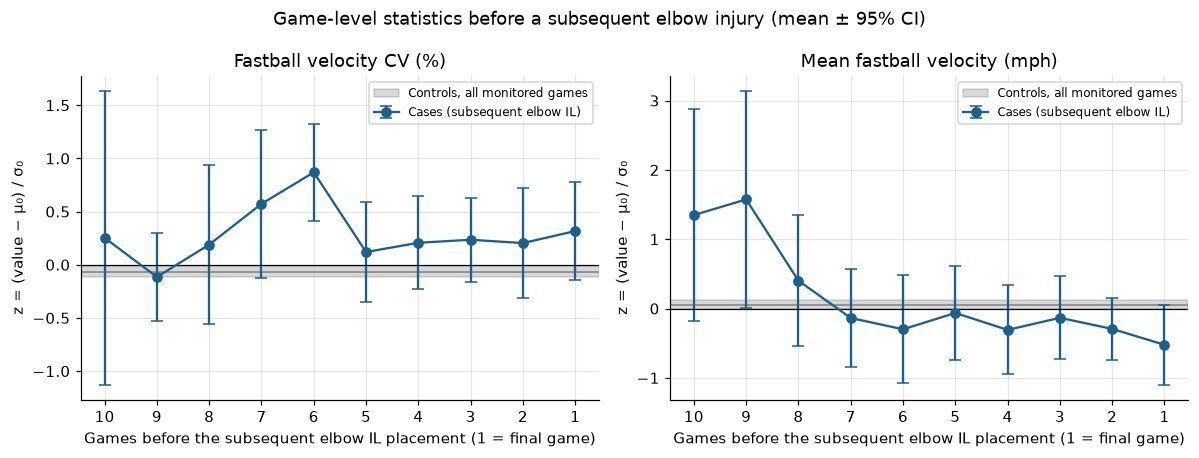

In [9]:
GAMES_BACK = 10
fig, axes = plt.subplots(1, len(METRICS), figsize=(5.5 * len(METRICS), 4.2), squeeze=False)
descriptive_rows = []
for ax, (m, spec) in zip(axes[0], METRICS.items()):
    ctrl = np.concatenate([unit_data[u]["z"][m] for u in units.loc[units["case"] == 0, "uid"]] or [[]])
    case_rows = []
    for u in units.loc[units["case"] == 1, "uid"]:
        z = unit_data[u]["z"][m]
        for back, value in enumerate(z[::-1][:GAMES_BACK], start=1):
            case_rows.append({"games_before_IL": back, "z": value})
    cz = pd.DataFrame(case_rows, columns=["games_before_IL", "z"])
    s = cz.groupby("games_before_IL")["z"].agg(["mean", "std", "count"]).reindex(range(1, GAMES_BACK + 1))
    s["half"] = 1.96 * s["std"] / np.sqrt(s["count"])
    if len(ctrl):
        c_mean, c_half = ctrl.mean(), 1.96 * ctrl.std(ddof=1) / np.sqrt(len(ctrl))
        ax.axhspan(c_mean - c_half, c_mean + c_half, color="grey", alpha=0.3, label="Controls, all monitored games")
        ax.axhline(c_mean, color="grey", lw=1)
    ax.errorbar(s.index, s["mean"], yerr=s["half"], fmt="o-", color="#1f5f8b", capsize=4,
                label="Cases (subsequent elbow IL)")
    ax.axhline(0, color="black", lw=0.8)
    ax.invert_xaxis()
    ax.set_xticks(range(1, GAMES_BACK + 1))
    ax.set_xlabel("Games before the subsequent elbow IL placement (1 = final game)")
    ax.set_ylabel("z = (value − μ₀) / σ₀")
    ax.set_title(spec["label"])
    ax.legend(fontsize=8)
    descriptive_rows.append(s.assign(statistic=m).reset_index())
fig.suptitle("Game-level statistics before a subsequent elbow injury (mean ± 95% CI)")
fig.tight_layout()
save(fig, "E1_statistics_before_subsequent_elbow_IL")
pd.concat(descriptive_rows).to_csv(OUT_DIR / "descriptive_games_before_IL.csv", index=False)

## 8. EWMA-CUSUM charts on the training seasons

The chart below is checked against the NBA study's lower-sided form on random data, then run for every
(statistic, λ, h) on every training unit. A unit is a predicted positive if any monitored game signals.

In [10]:
def ewma_cusum(dev, lam):
    """One-sided EWMA-CUSUM on deviations already signed toward the hypothesis (signal if path > h)."""
    path = np.empty(len(dev))
    prev = 0.0
    for j, x in enumerate(dev):
        prev = max(0.0, lam * x + (1 - lam) * prev)
        path[j] = prev
    return path


def nba_lower(values, mu0, sigma0, lam):
    """The NBA study's statistic, written exactly as in its notebook (for the check below)."""
    stat, prev = [], 0.0
    for v in values:
        pci = (v - (mu0 - 2 * sigma0)) / sigma0
        prev = min(lam * (pci - 2) + (1 - lam) * prev, 0.0)
        stat.append(prev)
    return np.array(stat)


rng_check = np.random.default_rng(1)
vals = rng_check.normal(93, 1, 50)
for lam in (0.05, 0.45, 0.95):
    np.testing.assert_allclose(-nba_lower(vals, 93.2, 0.8, lam),
                               ewma_cusum(-(vals - 93.2) / 0.8, lam), atol=1e-12)
print("Chart matches the NBA study's lower-sided EWMA-CUSUM (sign-flipped).")


def run_grid(uids, m, lambdas, hs):
    """One row per (unit, lambda, h): signal yes/no and the monitored game of the first signal."""
    hs = np.asarray(hs)
    rows = []
    for u in uids:
        d = unit_data[u]
        case = int(units.at[u, "case"])
        for lam in lambdas:
            path = ewma_cusum(d["dev"][m], lam)
            over = path[None, :] > hs[:, None]
            signal = over.any(axis=1)
            first = np.where(signal, over.argmax(axis=1), -1)
            for h, s, f in zip(hs, signal, first):
                rows.append((u, case, m, lam, h, bool(s), int(f)))
    return pd.DataFrame(rows, columns=["uid", "case", "statistic", "lambda", "h", "signal", "first_signal"])


def confusion(results, by=("statistic", "lambda", "h")):
    g = results.assign(TP=results["signal"] & (results["case"] == 1),
                       FP=results["signal"] & (results["case"] == 0),
                       TN=~results["signal"] & (results["case"] == 0),
                       FN=~results["signal"] & (results["case"] == 1))
    s = g.groupby(list(by))[["TP", "FP", "TN", "FN"]].sum().reset_index()
    with np.errstate(invalid="ignore", divide="ignore"):
        s["Sensitivity"] = s["TP"] / (s["TP"] + s["FN"])
        s["Specificity"] = s["TN"] / (s["TN"] + s["FP"])
        s["PPV"] = s["TP"] / (s["TP"] + s["FP"])
        s["NPV"] = s["TN"] / (s["TN"] + s["FN"])
        s["Accuracy"] = (s["TP"] + s["TN"]) / (s["TP"] + s["FP"] + s["TN"] + s["FN"])
    s["Youden"] = s["Sensitivity"] + s["Specificity"] - 1
    return s


train_results = pd.concat([run_grid(train_uids, m, LAMBDA_GRID, H_GRID) for m in METRICS], ignore_index=True)
train_summary = confusion(train_results)
train_summary.to_csv(OUT_DIR / "train_grid_summary.csv", index=False)
n_case_train = int(units.loc[units["split"] == "train", "case"].sum())
print(f"Training units: {len(train_uids)} ({n_case_train} cases, {len(train_uids) - n_case_train} controls)")
display(train_summary.sort_values(["statistic", "Accuracy"], ascending=[True, False])
                     .groupby("statistic").head(5).round(3))

Chart matches the NBA study's lower-sided EWMA-CUSUM (sign-flipped).
Training units: 150 (25 cases, 125 controls)


,statistic,lambda,h,TP,FP,TN,FN,Sensitivity,Specificity,PPV,NPV,Accuracy,Youden
9,cv,0.45,0.50,13,71,54,12,0.52,0.432,0.155,0.818,0.447,-0.048
8,cv,0.45,0.45,14,74,51,11,0.56,0.408,0.159,0.823,0.433,-0.032
19,cv,0.55,0.50,14,79,46,11,0.56,0.368,0.151,0.807,0.400,-0.072
7,cv,0.45,0.40,14,80,45,11,0.56,0.360,0.149,0.804,0.393,-0.080
18,cv,0.55,0.45,14,82,43,11,0.56,0.344,0.146,0.796,0.380,-0.096
68,velo,0.45,0.45,13,81,44,12,0.52,0.352,0.138,0.786,0.380,-0.128
69,velo,0.45,0.50,13,81,44,12,0.52,0.352,0.138,0.786,0.380,-0.128
67,velo,0.45,0.40,16,86,39,9,0.64,0.312,0.157,0.812,0.367,-0.048
79,velo,0.55,0.50,14,85,40,11,0.56,0.320,0.141,0.784,0.360,-0.120
78,velo,0.55,0.45,16,88,37,9,0.64,0.296,0.154,0.804,0.353,-0.064


### Block-bootstrap false-alarm check

Synthetic "healthy" sequences are built from training units' own baseline games (standardized with the
frozen baseline, resampled in overlapping blocks of 3 to keep short-range dependence), each as long as a
randomly chosen training control's monitored series. If the observed false-positive rate among training
controls is at or below the bootstrap rate, the chart is not alarming more often than chance would
explain on in-control data.

In [11]:
rng = np.random.default_rng(SEED)
control_lengths = units.loc[(units["split"] == "train") & (units["case"] == 0), "monitored_games"].to_numpy()
null_rows = []
for m in METRICS:
    pools = [unit_data[u]["baseline_dev"][m] for u in train_uids if len(unit_data[u]["baseline_dev"][m]) >= BLOCK_LEN]
    if not pools or not len(control_lengths):
        continue
    starts = [(i, s) for i, p in enumerate(pools) for s in range(len(p) - BLOCK_LEN + 1)]
    seqs = []
    for L in rng.choice(control_lengths, size=N_NULL_SEQUENCES):
        blocks = [pools[i][s:s + BLOCK_LEN] for i, s in (starts[j] for j in rng.integers(len(starts), size=-(-L // BLOCK_LEN)))]
        seqs.append(np.concatenate(blocks)[:L])
    for lam in LAMBDA_GRID:
        peaks = np.array([ewma_cusum(s, lam).max() for s in seqs])
        for h in H_GRID:
            null_rows.append({"statistic": m, "lambda": lam, "h": h, "bootstrap_false_alarm": (peaks > h).mean()})
null_check = train_summary.merge(pd.DataFrame(null_rows), on=["statistic", "lambda", "h"])
null_check["observed_false_positive_rate"] = 1 - null_check["Specificity"]
null_check["observed_at_or_below_bootstrap"] = (null_check["observed_false_positive_rate"]
                                                <= null_check["bootstrap_false_alarm"] + 1e-12)
null_check.to_csv(OUT_DIR / "block_bootstrap_false_alarm.csv", index=False)
display(null_check.groupby("statistic")["observed_at_or_below_bootstrap"].agg(["mean", "size"])
                  .rename(columns={"mean": "share of grid at or below bootstrap", "size": "grid points"}))

,share of grid at or below bootstrap,grid points
statistic,,
cv,1.0,60
velo,1.0,60


### Selected (λ, h) per statistic, training seasons only

Selection rule from the NBA study: highest training accuracy (ties: higher sensitivity, then smaller h).
With few cases, accuracy can favour a chart that almost never signals, so the Youden-optimal point is
shown alongside it.

In [12]:
def select(summary, rule):
    key = "Accuracy" if rule == "accuracy" else "Youden"
    ranked = summary.dropna(subset=[key]).sort_values(
        ["statistic", key, "Sensitivity", "h"], ascending=[True, False, False, True])
    return ranked.groupby("statistic").head(1).set_index("statistic")


selected = {rule: select(train_summary, rule) for rule in ["accuracy", "youden"]}
display(pd.concat({r: s[["lambda", "h", "TP", "FP", "TN", "FN", "Sensitivity", "Specificity",
                         "PPV", "Accuracy", "Youden"]] for r, s in selected.items()}, names=["rule"]).round(3))
chosen = selected[SELECTION_RULE]
print("Rule used for the held-out season:", SELECTION_RULE)
for m, r in chosen.iterrows():
    if r["h"] in (H_GRID.min(), H_GRID.max()) or r["lambda"] in (LAMBDA_GRID.min(), LAMBDA_GRID.max()):
        print(f"Note: the {m} selection (λ = {r['lambda']:.2f}, h = {r['h']:.2f}) is on the edge of the grid, "
              "so the best setting may lie outside it. The wide-grid Youden pick is shown with the ROC below.")

lambda     h  TP  FP  TN  FN  Sensitivity  Specificity  \
rule     statistic                                                           
accuracy cv           0.45  0.50  13  71  54  12         0.52        0.432   
         velo         0.45  0.45  13  81  44  12         0.52        0.352   
youden   cv           0.45  0.45  14  74  51  11         0.56        0.408   
         velo         0.65  0.45  17  89  36   8         0.68        0.288   

                      PPV  Accuracy  Youden  
rule     statistic                           
accuracy cv         0.155     0.447  -0.048  
         velo       0.138     0.380  -0.128  
youden   cv         0.159     0.433  -0.032  
         velo       0.160     0.353  -0.032

Rule used for the held-out season: accuracy
Note: the cv selection (λ = 0.45, h = 0.50) is on the edge of the grid, so the best setting may lie outside it. The wide-grid Youden pick is shown with the ROC below.
Note: the velo selection (λ = 0.45, h = 0.45) is on the edge of the grid, so the best setting may lie outside it. The wide-grid Youden pick is shown with the ROC below.


### Heatmaps: training sensitivity and specificity across (λ, h)

In [ ]:
fig, axes = plt.subplots(len(METRICS), 2, figsize=(10, 3.6 * len(METRICS)), squeeze=False)
for row, (m, spec) in enumerate(METRICS.items()):
    for col, measure in enumerate(["Sensitivity", "Specificity"]):
        ax = axes[row, col]
        grid = (train_summary.loc[train_summary["statistic"] == m]
                             .pivot(index="lambda", columns="h", values=measure))
        im = ax.imshow(grid.to_numpy(float), cmap="Greys", vmin=0, vmax=1, aspect="auto", origin="lower")
        ax.set_xticks(range(len(grid.columns)), [f"{h:.2f}" for h in grid.columns], rotation=90, fontsize=8)
        ax.set_yticks(range(len(grid.index)), [f"{l:.2f}" for l in grid.index], fontsize=8)
        for i in range(grid.shape[0]):
            for j in range(grid.shape[1]):
                v = grid.iat[i, j]
                if np.isfinite(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                            color="white" if v > 0.6 else "black")
        ax.grid(False)
        ax.set_xlabel("Threshold (h)")
        ax.set_ylabel("Smoothing weight (λ)")
        ax.set_title(f"{spec['label']} — {measure}", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.6)
save(fig, "E2_train_grid_heatmaps")

### ROC frontier and AUC (training seasons, wide h grid)

As in the NBA study, the ROC curve for each chart is the Pareto frontier of the (λ, h) grid, anchored at
(0, 0) and (1, 1); AUC is the trapezoidal area under it. The low-λ grid (0.05–0.35) is shown as a
sensitivity check: smaller λ remembers more past games, which is what a small, persistent shift needs.

In [ ]:
def roc_frontier(summary):
    pts = summary.assign(FPR=1 - summary["Specificity"])[["FPR", "Sensitivity"]].dropna().to_numpy()
    pts = np.vstack([[0, 0], pts, [1, 1]])
    pts = pts[np.lexsort((-pts[:, 1], pts[:, 0]))]
    frontier, best = [], -1.0
    for fpr, sens in pts:
        if sens > best:
            frontier.append((fpr, sens))
            best = sens
    frontier = np.array(frontier)
    if frontier[-1, 0] < 1:
        frontier = np.vstack([frontier, [1, best]])
    return frontier, np.trapezoid(frontier[:, 1], frontier[:, 0]) if hasattr(np, "trapezoid") else np.trapz(frontier[:, 1], frontier[:, 0])


wide = {}
for grid_name, lambdas in [("λ 0.45–0.95 (NBA)", LAMBDA_GRID), ("λ 0.05–0.35", LAMBDA_GRID_LOW)]:
    res = pd.concat([run_grid(train_uids, m, lambdas, H_GRID_WIDE) for m in METRICS], ignore_index=True)
    wide[grid_name] = confusion(res)

fig, axes = plt.subplots(1, len(METRICS), figsize=(5.2 * len(METRICS), 4.6), squeeze=False)
auc_rows = []
for ax, (m, spec) in zip(axes[0], METRICS.items()):
    for (grid_name, summ), style in zip(wide.items(), ["-", "--"]):
        frontier, auc = roc_frontier(summ.loc[summ["statistic"] == m])
        ax.step(frontier[:, 0], frontier[:, 1], where="post", ls=style, lw=1.8, label=f"{grid_name}: AUC {auc:.2f}")
        auc_rows.append({"statistic": m, "grid": grid_name, "AUC": auc})
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set_xlabel("False-positive rate (1 − specificity)")
    ax.set_ylabel("Sensitivity")
    ax.set_title(spec["label"])
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("ROC frontier across (λ, h), training seasons")
fig.tight_layout()
save(fig, "E3_train_roc")
auc_table = pd.DataFrame(auc_rows)
auc_table.to_csv(OUT_DIR / "train_roc_auc.csv", index=False)
display(auc_table.pivot(index="statistic", columns="grid", values="AUC").round(3))
wide_picks = pd.concat({g: select(summ, "youden") for g, summ in wide.items()}, names=["grid"])
print("Youden-optimal (λ, h) on the wide h grid (training seasons):")
display(wide_picks[["lambda", "h", "TP", "FP", "TN", "FN", "Sensitivity", "Specificity", "PPV", "Youden"]].round(3))

## 9. Held-out season: one application of the frozen model

Baseline parameters ($G$, $k$, $\sigma_0$) and the selected (λ, h) come from the training seasons.
This is the only cell that evaluates the held-out season. Intervals are Wilson 95% intervals (better
behaved than Wald with small counts).

In [ ]:
def wilson(successes, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


test_uids = units.loc[units["split"] == "test", "uid"].tolist()
eval_rows, eval_results = [], []
for split, uids in [("train", train_uids), ("test", test_uids)]:
    for m in METRICS:
        lam, h = chosen.loc[m, "lambda"], chosen.loc[m, "h"]
        res = run_grid(uids, m, [lam], [h])
        eval_results.append(res.assign(split=split))
        s = confusion(res).iloc[0] if len(res) else None
        if s is None:
            continue
        sl, su = wilson(s["TP"], s["TP"] + s["FN"])
        pl, pu = wilson(s["TN"], s["TN"] + s["FP"])
        eval_rows.append({"split": split, "statistic": m, "lambda": lam, "h": h,
                          **{k: int(s[k]) for k in ["TP", "FP", "TN", "FN"]},
                          "Sensitivity": s["Sensitivity"], "Sens 95% CI": f"{sl:.2f}–{su:.2f}",
                          "Specificity": s["Specificity"], "Spec 95% CI": f"{pl:.2f}–{pu:.2f}",
                          "PPV": s["PPV"], "NPV": s["NPV"], "Accuracy": s["Accuracy"]})
heldout = pd.DataFrame(eval_rows)
heldout.to_csv(OUT_DIR / "heldout_evaluation.csv", index=False)
eval_results = pd.concat(eval_results, ignore_index=True)
n_case_test = int(units.loc[units["split"] == "test", "case"].sum())
print(f"Held-out units: {len(test_uids)} ({n_case_test} cases)")
display(heldout.round(3))

### Lead time: first signal to the subsequent elbow IL placement (true positives)

Games = appearances from the signal game through his final game before the IL date (1 = signal in the
final game). Days = IL date minus the date of the signal game.

In [ ]:
lead_rows = []
tp = eval_results.loc[eval_results["signal"] & (eval_results["case"] == 1)]
for _, r in tp.iterrows():
    d = unit_data[r["uid"]]
    game = d["monitored"].iloc[r["first_signal"]]
    lead_rows.append({"split": r["split"], "statistic": r["statistic"], "Name": units.at[r["uid"], "Name"],
                      "Season": units.at[r["uid"], "Season"],
                      "lead_games": d["n_apps_before_stop"] - int(game["app_index"]),
                      "lead_days": (units.at[r["uid"], "event_date"] - game["game_date"]).days})
lead = pd.DataFrame(lead_rows, columns=["split", "statistic", "Name", "Season", "lead_games", "lead_days"])
lead.to_csv(OUT_DIR / "lead_time_true_positives.csv", index=False)
if len(lead):
    display(lead.groupby(["split", "statistic"])[["lead_games", "lead_days"]]
                .agg(["count", "median", "mean"]).round(1))
else:
    print("No true positives at the selected settings.")

## 10. Example control charts

One case and one control for each statistic at the selected (λ, h): a case that signalled (held-out
season if possible), and the control with the median peak. **Top:** the game value with the shrunk
baseline $\mu_0$ and $\mu_0 \pm 2\sigma_0$. **Bottom:** the EWMA-CUSUM with the threshold h; the orange line
marks the subsequent elbow IL date.

In [ ]:
def pick_examples(m):
    lam, h = chosen.loc[m, "lambda"], chosen.loc[m, "h"]
    res = eval_results.loc[eval_results["statistic"] == m]
    tp_ids = res.loc[res["signal"] & (res["case"] == 1)].sort_values("split")["uid"].tolist()
    cases = units.loc[units["case"] == 1, "uid"].tolist()
    case_uid = tp_ids[0] if tp_ids else (cases[0] if cases else None)
    controls = units.loc[units["case"] == 0, "uid"].tolist()
    peaks = {u: ewma_cusum(unit_data[u]["dev"][m], lam).max() for u in controls}
    ctrl_uid = min(peaks, key=lambda u: abs(peaks[u] - np.median(list(peaks.values())))) if peaks else None
    return [u for u in (case_uid, ctrl_uid) if u is not None], lam, h


for m, spec in METRICS.items():
    examples, lam, h = pick_examples(m)
    if not examples:
        continue
    fig, axes = plt.subplots(2, len(examples), figsize=(6 * len(examples), 6), sharex="col", squeeze=False,
                             gridspec_kw={"height_ratios": [1.2, 1]})
    for col, u in enumerate(examples):
        d, row = unit_data[u], units.loc[units["uid"] == u].iloc[0]
        mon = d["monitored"]
        x = np.arange(1, len(mon) + 1)
        top, bot = axes[0, col], axes[1, col]
        mu0, sig = d["mu0"][m], d["sigma"][m]
        top.plot(x, mon[m], "o-", color="#1f5f8b", ms=4)
        top.plot(x, np.full(len(x), mu0), color="black", lw=1, label="μ₀ (shrunk baseline)")
        top.plot(x, mu0 + 2 * sig, color="black", ls="--", lw=0.8, label="μ₀ ± 2σ₀")
        top.plot(x, mu0 - 2 * sig, color="black", ls="--", lw=0.8)
        path = ewma_cusum(d["dev"][m], lam)
        bot.step(x, path, where="mid", color="#1f5f8b")
        bot.axhline(h, color="red", ls="--", lw=1, label=f"h = {h:.2f}")
        over = np.flatnonzero(path > h)
        if len(over):
            for axis in (top, bot):
                axis.axvline(over[0] + 1, color="red", alpha=0.5)
        if row["case"]:
            for axis in (top, bot):
                axis.axvline(len(x) + 0.5, color="darkorange", lw=2,
                             label="Subsequent elbow IL" if axis is bot else None)
        kind = "Case" if row["case"] else "Control"
        top.set_title(f"{kind}: {row['Name']} {row['Season']} ({row['split']})\n"
                      f"initial: {row['initial_injury']}"
                      + (f" | next: {row['next_injury']}" if isinstance(row['next_injury'], str) else ""),
                      fontsize=9)
        top.set_ylabel(spec["label"])
        bot.set_ylabel("EWMA-CUSUM" + (" (lower side, sign-flipped)" if spec["side"] == "lower" else ""))
        bot.set_xlabel("Monitored game since return")
        top.legend(fontsize=7)
        bot.legend(fontsize=7)
    fig.suptitle(f"{spec['label']}: λ = {lam:.2f}, h = {h:.2f}")
    fig.tight_layout()
    save(fig, f"E4_example_chart_{m}")

## 11. Notes for interpretation

* **Sample size.** Check the cohort table in Section 5 first. With few cases per season, sensitivity
  intervals are wide and the held-out result is a single noisy draw.
* **Same pitcher, several seasons.** A pitcher can contribute more than one unit (different seasons). The
  confusion-matrix summaries treat units as independent, as in the NBA study.
* **The IL date is not the injury date.** The final monitored game is often the game in which the injury
  happened, so a signal there is closer to detection than warning. Lead times of one game should be read
  that way.
* **CV and mean velocity answer different questions.** CV divides out the level, so it tracks *consistency*;
  the mean tracks *level*. The replication notebook found the arm signal in the level (about 0.5–0.7 mph
  below normal in the final game before an arm reinjury).
* **Things to vary** (Settings cell): `CV_FIRST_N` (e.g. 20, to make starters and relievers comparable),
  `SIGMA_MODE = "per_fb"`, `MIN_FB_GAME`, `SELECTION_RULE = "youden"`, and the elbow pattern.